# Aula 10 — Matplotlib e Seaborn: construção e refinamento de visualizações

Fund. de Programação, Dados e Estatística para IA · Einstein Hospital Israelita

## 01 · Da escolha à construção

### Bibliotecas, tema e leitura da base

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
#
#testar ["whitegrid", "darkgrid", "dark", "white", "ticks"]

### Outros parâmetros do `set_theme`

`sns.set_theme(style="ticks", context="talk", palette="pastel")`

- **`context`** ajusta o tamanho de fontes e linhas: `"paper"` (menor), `"notebook"` (padrão), `"talk"` e `"poster"` (maior). É útil para slides.
- **`palette`** muda as cores: `"deep"` (padrão), `"muted"`, `"pastel"`, `"bright"`, `"dark"`, `"colorblind"`.

In [2]:
df = pd.read_csv("pacientes_aula8_analise.csv")

df.head()

,id_paciente,idade,faixa_etaria,servico,tempo_internacao_dias,internacoes_anteriores,readmissao_30d
0,P0001,60.0,60 ou mais,Cardiologia,3.0,2,0
1,P0002,39.0,18 a 59,Clínica Médica,6.0,0,0
2,P0003,83.0,60 ou mais,Clínica Médica,2.0,1,0
3,P0004,45.0,18 a 59,Oncologia,16.0,0,0
4,P0005,55.0,18 a 59,Clínica Médica,4.0,0,0


### A estrutura de uma figura: Figure e Axes

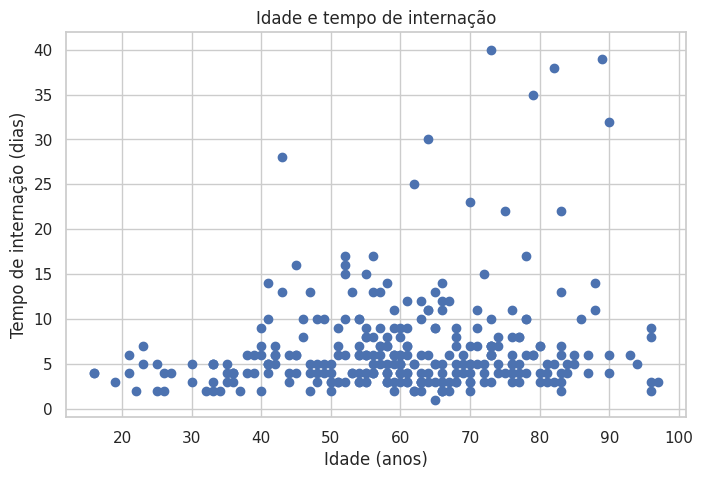

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(df["idade"], df["tempo_internacao_dias"])
ax.set_xlabel("Idade (anos)")
ax.set_ylabel("Tempo de internação (dias)")
ax.set_title("Idade e tempo de internação")

plt.show()

## 02 · Distribuição e comparação

### Histograma refinado

**Pergunta:** como se distribui o tempo de internação?

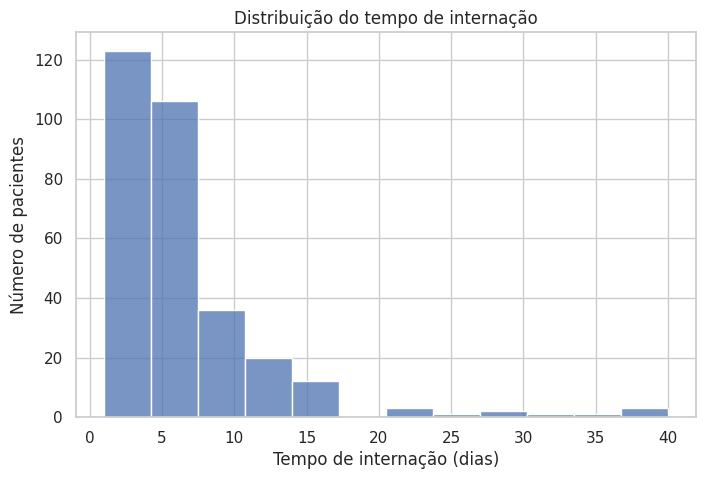

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=df,
    x="tempo_internacao_dias",
    bins=12,
    ax=ax
)

ax.set_title("Distribuição do tempo de internação")
ax.set_xlabel("Tempo de internação (dias)")
ax.set_ylabel("Número de pacientes")

plt.show()

### A conclusão muda com os bins?

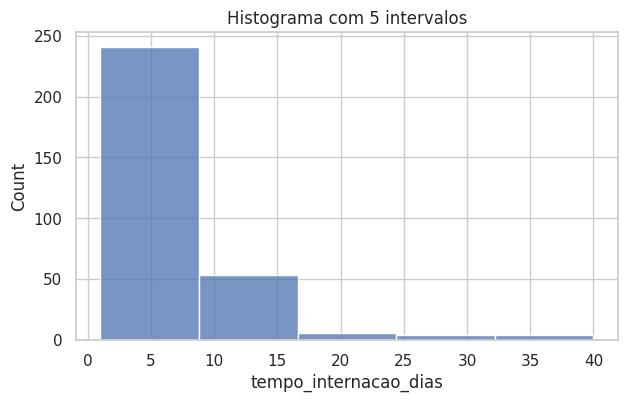

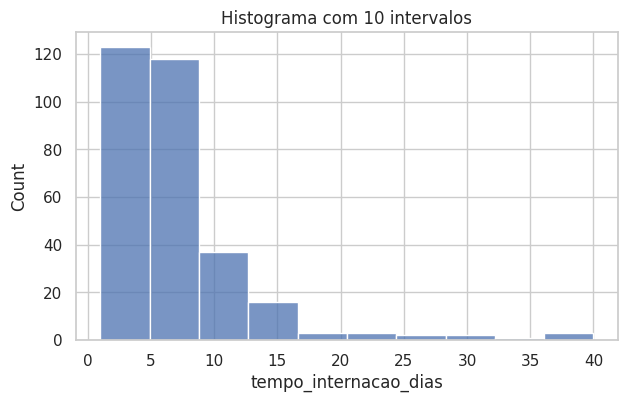

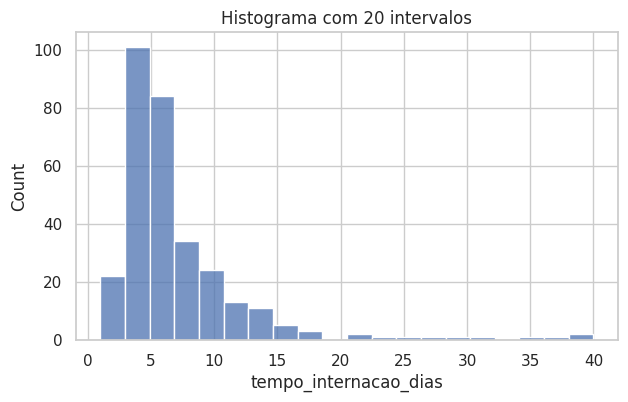

In [5]:
for bins in [5, 10, 20]:
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.histplot(data=df, x="tempo_internacao_dias",
                 bins=bins, ax=ax)
    ax.set_title(f"Histograma com {bins} intervalos")
    plt.show()

*Anotação:* a conclusão sobre assimetria e concentração muda, ou só o nível de detalhe visual?

### Comparando distribuições com boxplot

**Pergunta:** o tempo de internação difere entre readmitidos e não readmitidos?

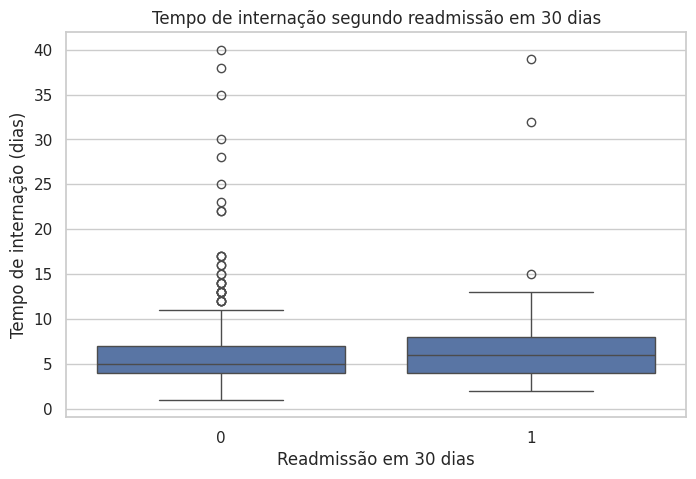

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="readmissao_30d",
    y="tempo_internacao_dias",
    ax=ax
)

ax.set_title("Tempo de internação segundo readmissão em 30 dias")
ax.set_xlabel("Readmissão em 30 dias")
ax.set_ylabel("Tempo de internação (dias)")

plt.show()

### Resumo e observações na mesma figura

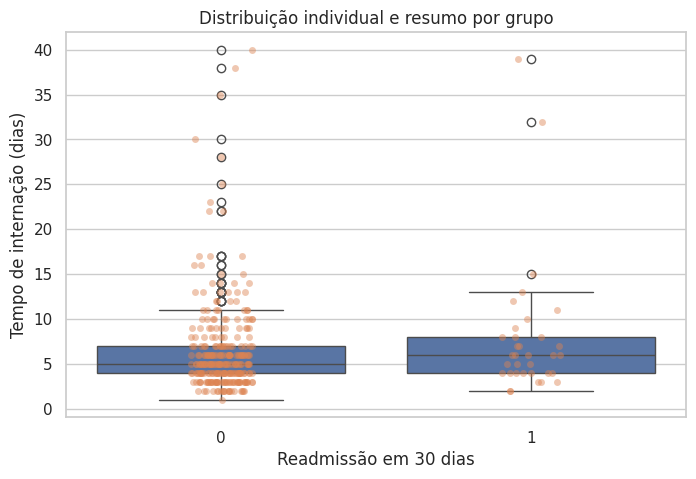

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=df, x="readmissao_30d",
            y="tempo_internacao_dias", ax=ax)
sns.stripplot(data=df, x="readmissao_30d",
              y="tempo_internacao_dias",
              alpha=0.45, ax=ax)

ax.set_title("Distribuição individual e resumo por grupo")
ax.set_xlabel("Readmissão em 30 dias")
ax.set_ylabel("Tempo de internação (dias)")

plt.show()

## 03 · Barras e séries temporais

### Barras: taxa de readmissão por serviço

In [8]:
taxa_servico = (
    df.groupby("servico")
      ["readmissao_30d"]
      .mean()
      .reset_index(
          name="taxa_readmissao"
      )
)

taxa_servico

,servico,taxa_readmissao
0,Cardiologia,0.027397
1,Clínica Médica,0.138298
2,Neurologia,0.159091
3,Oncologia,0.137255
4,Ortopedia,0.086207


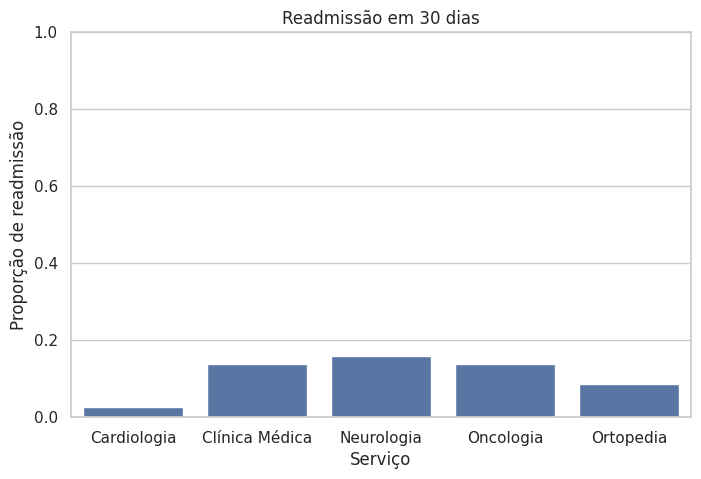

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=taxa_servico,
            x="servico",
            y="taxa_readmissao",
            errorbar=None, ax=ax)
ax.set_title("Readmissão em 30 dias")
ax.set_xlabel("Serviço")
ax.set_ylabel("Proporção de readmissão")
ax.set_ylim(0, 1)
plt.show()

*Anotação:* quantos pacientes há em cada serviço? Barras iguais podem ter confiabilidade diferente.

## 04 · Relações e referências

### Dispersão com grupos

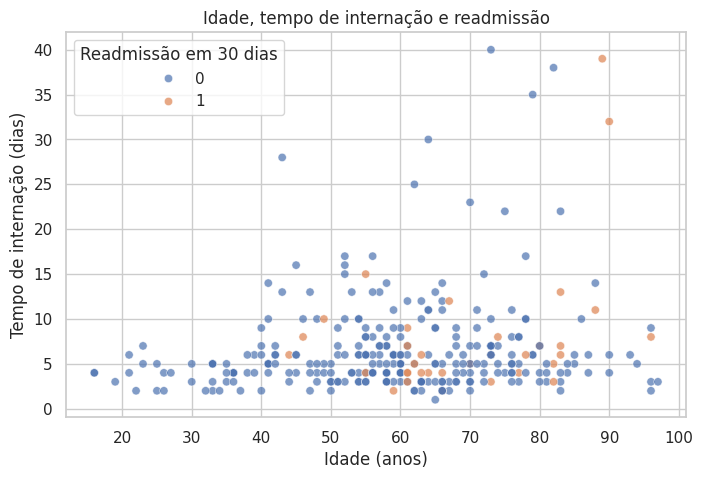

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(data=df, x="idade",
                y="tempo_internacao_dias",
                hue="readmissao_30d", alpha=0.7, ax=ax)

ax.set_title("Idade, tempo de internação e readmissão")
ax.set_xlabel("Idade (anos)")
ax.set_ylabel("Tempo de internação (dias)")
ax.legend(title="Readmissão em 30 dias")

plt.show()

### Linhas de referência

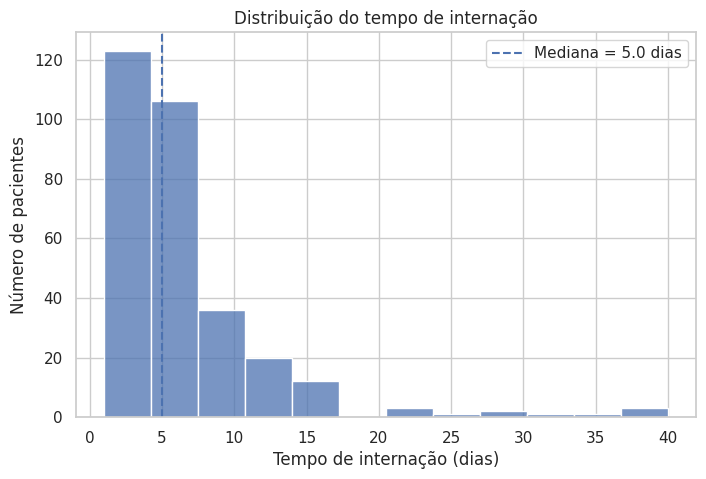

In [11]:
mediana = df["tempo_internacao_dias"].median()

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x="tempo_internacao_dias",
             bins=12, ax=ax)
ax.axvline(mediana, linestyle="--",
           label=f"Mediana = {mediana:.1f} dias")

ax.set_title("Distribuição do tempo de internação")
ax.set_xlabel("Tempo de internação (dias)")
ax.set_ylabel("Número de pacientes")
ax.legend()
plt.show()

### Matriz de correlação com Seaborn

In [12]:
variaveis = [
    "idade",
    "tempo_internacao_dias",
    "readmissao_30d"
]

corr = df[variaveis].corr()
corr

,idade,tempo_internacao_dias,readmissao_30d
idade,1.000000,0.187789,0.202002
tempo_internacao_dias,0.187789,1.000000,0.074032
readmissao_30d,0.202002,0.074032,1.000000


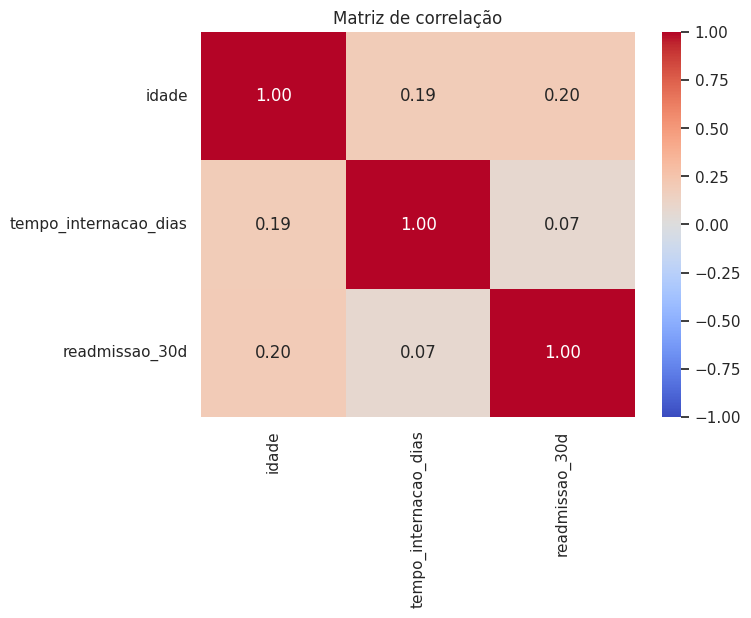

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            ax=ax)
ax.set_title("Matriz de correlação")
plt.show()

## 05 · Escala, rótulos e cor

### A figura se explica sozinha: de 0/1 para Não/Sim

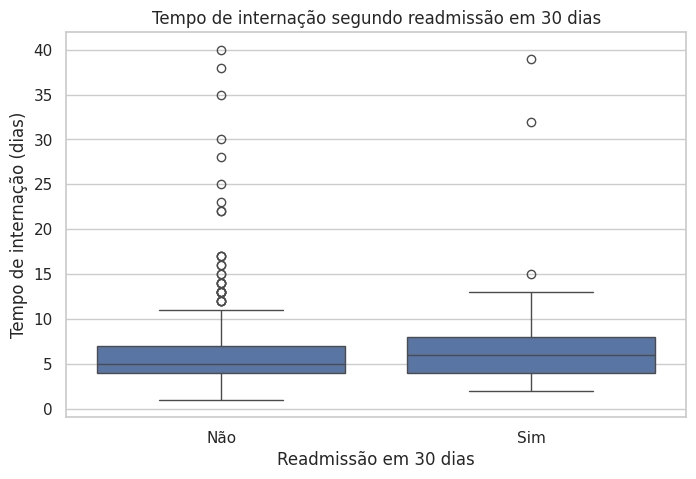

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=df, x="readmissao_30d",
            y="tempo_internacao_dias", ax=ax)

ax.set_title("Tempo de internação segundo readmissão em 30 dias")
ax.set_xlabel("Readmissão em 30 dias")
ax.set_ylabel("Tempo de internação (dias)")
ax.set_xticks([0, 1], labels=["Não", "Sim"])

plt.show()

## 06 · Painéis, exportação e reprodutibilidade

### Múltiplos painéis

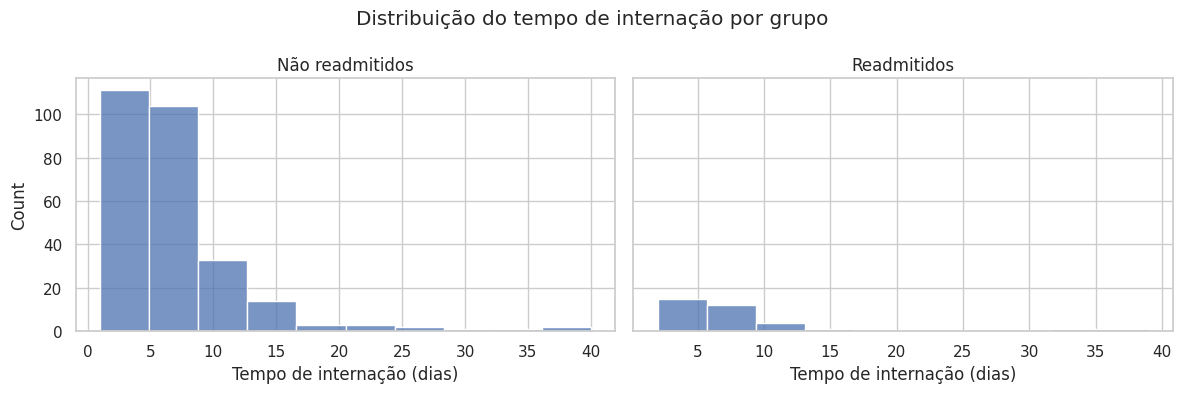

In [15]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 4),
    sharey=True
)

sns.histplot(
    data=df[df["readmissao_30d"] == 0],
    x="tempo_internacao_dias",
    bins=10,
    ax=axes[0]
)
axes[0].set_title("Não readmitidos")
axes[0].set_xlabel("Tempo de internação (dias)")

sns.histplot(
    data=df[df["readmissao_30d"] == 1],
    x="tempo_internacao_dias",
    bins=10,
    ax=axes[1]
)
axes[1].set_title("Readmitidos")
axes[1].set_xlabel("Tempo de internação (dias)")

fig.suptitle("Distribuição do tempo de internação por grupo")
fig.tight_layout()
plt.show()

### Exportando a partir do código

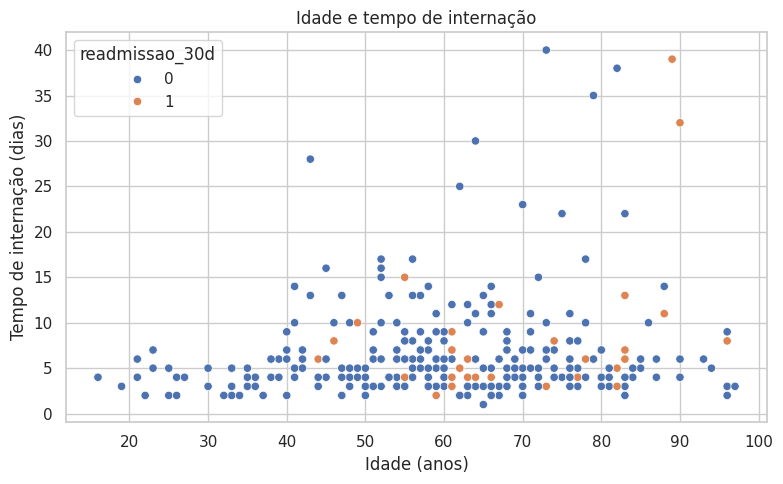

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="idade",
                y="tempo_internacao_dias",
                hue="readmissao_30d", ax=ax)
ax.set_title("Idade e tempo de internação")
ax.set_xlabel("Idade (anos)")
ax.set_ylabel("Tempo de internação (dias)")

fig.tight_layout()
fig.savefig("idade_tempo_internacao.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Funções evitam repetição no código gráfico

In [17]:
def formatar_grafico(ax, titulo,
                     xlabel, ylabel):
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return ax

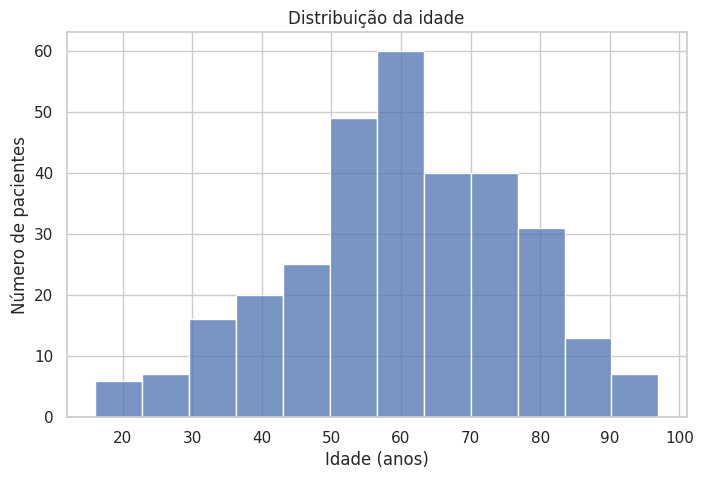

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x="idade",
             bins=12, ax=ax)

formatar_grafico(
    ax,
    "Distribuição da idade",
    "Idade (anos)",
    "Número de pacientes"
)

plt.show()